# Test de prévision

**Question du manager :** ces données permettent-elles de prévoir, pour chaque groupe, les ventes du mois qui suit le dernier mois complet (septembre 2019, donc octobre 2019) ?

**Protocole.** On se place dans le passé : pour chacun des 24 derniers mois complets (octobre 2017 à septembre 2019), on prévoit le mois en n'utilisant que les mois qui le précèdent, puis on compare au réel. Trois méthodes sont testées sur exactement les mêmes mois :

- **Naïve 1** : le mois prochain = ce mois-ci.
- **Naïve 2** : le mois prochain = le même mois l'an dernier.
- **Modèle** : lissage exponentiel saisonnier (Holt-Winters, tendance amortie, saisonnalité additive de 12 mois), écrit avec `numpy` pour ne dépendre d'aucune bibliothèque supplémentaire. Ses réglages sont choisis à chaque prévision sur les seuls mois d'avant.

L'erreur est l'écart absolu moyen (MAE) entre prévu et réel, en unités du logiciel de caisse (non documentées : pas de comparaison de volume entre groupes). La méthode et la grille de réglages sont fixées avant le test, pas ajustées après avoir vu les erreurs.

### Chargement des données mensuelles
On garde les mois complets et on vérifie qu'il n'en manque aucun.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


m = pd.read_csv("data/clean/ventes_mensuel.csv", encoding="utf-8-sig", parse_dates=["date_fin_mois"])
m = m[m["mois_complet"]].set_index("date_fin_mois").sort_index()
groupes = [c for c in m.columns if c.endswith(")")]      # les 8 colonnes "Nom (code)"
y = m[groupes]

assert (np.diff(y.index.year * 12 + y.index.month) == 1).all(), "il manque un mois"
print(len(y), "mois complets :", y.index.min().date(), "->", y.index.max().date())

68 mois complets : 2014-02-28 -> 2019-09-30


Ventes mensuelles par groupe
La courbe de chaque groupe, pour voir la saison et la tendance.

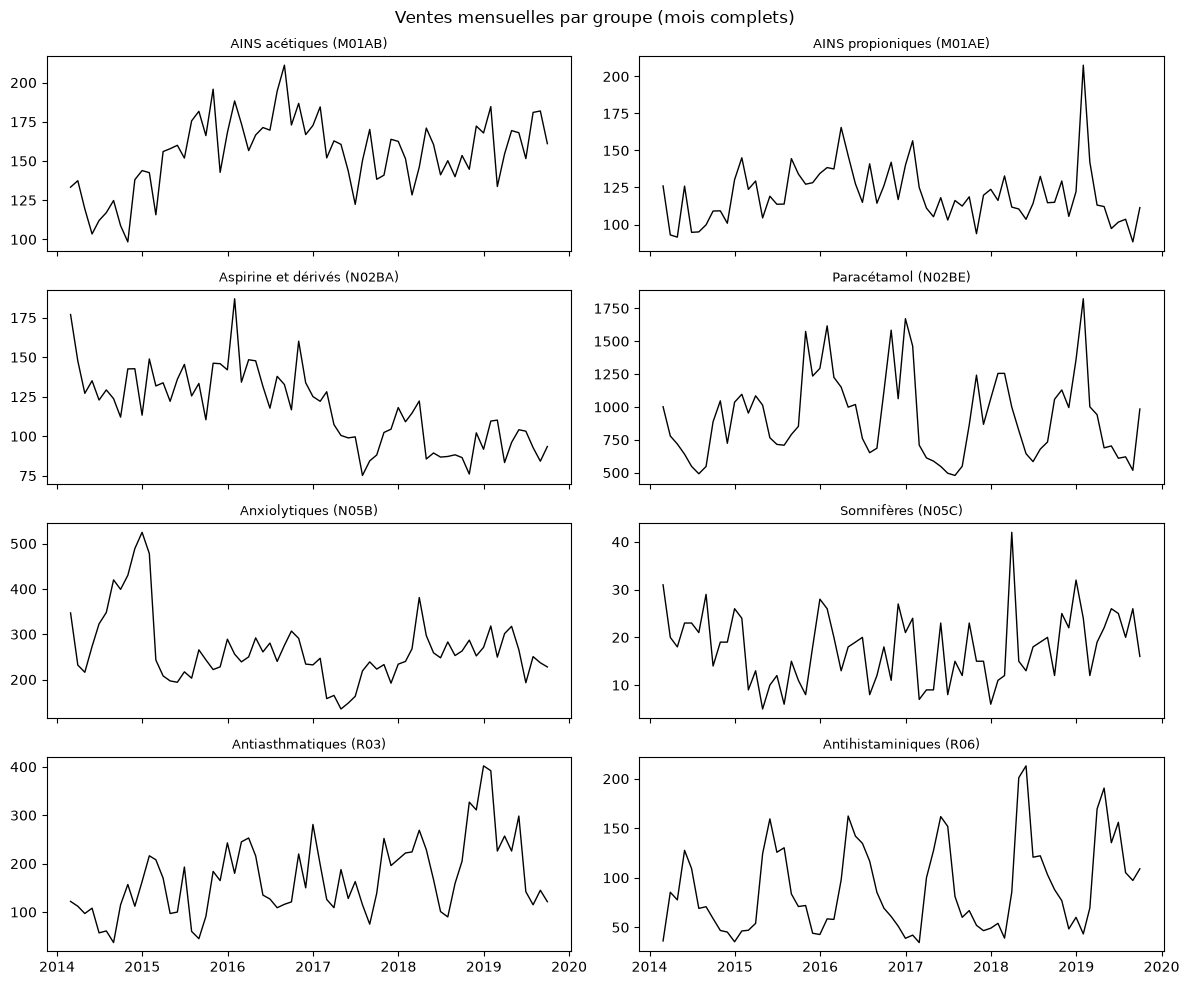

In [2]:
fig, axes = plt.subplots(4, 2, figsize=(12, 10), sharex=True)
for ax, g in zip(axes.ravel(), groupes):
    ax.plot(y.index, y[g], color="black", linewidth=1)
    ax.set_title(g, fontsize=9)
fig.suptitle("Ventes mensuelles par groupe (mois complets)")
plt.tight_layout()
plt.show()

Fichier mensuel contre journalier
On compare le fichier mensuel à la somme du journalier pour repérer les écarts.

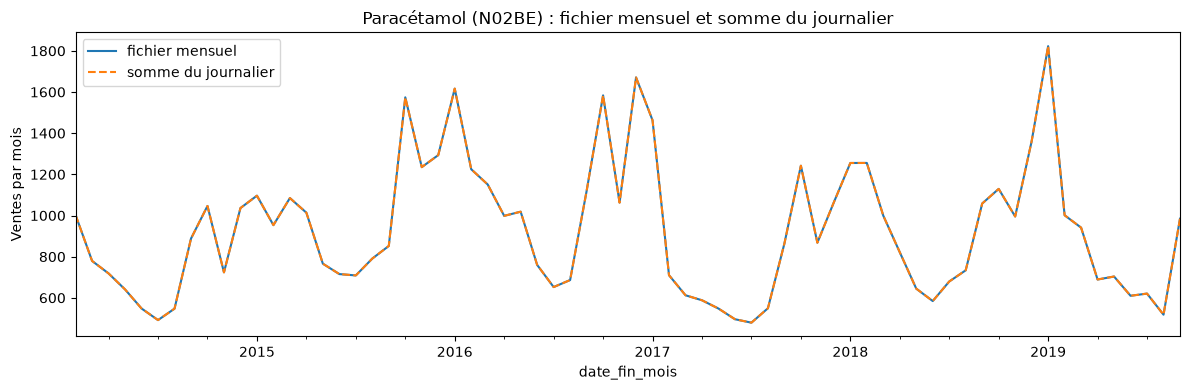

In [3]:
d = pd.read_csv("data/clean/ventes_journalier.csv", encoding="utf-8-sig", parse_dates=["date"])
d = d[d["journee_complete"]]
j = d.groupby(d["date"].dt.to_period("M"))[groupes].sum()
j.index = j.index.to_timestamp(how="end").normalize()
col = [c for c in groupes if "N02BE" in c][0]
comp = pd.DataFrame({"fichier mensuel": y[col], "somme du journalier": j[col].reindex(y.index)})
fig, ax = plt.subplots(figsize=(12, 4))
comp.plot(ax=ax, style=["-", "--"])
ax.set_title(f"{col} : fichier mensuel et somme du journalier"); ax.set_ylabel("Ventes par mois")
plt.tight_layout(); plt.show()

### Modèle de prévision et test sur 24 mois
On prévoit chacun des 24 derniers mois avec seulement les mois d'avant, avec le modèle et deux prévisions simples (le mois précédent et le même mois l'an dernier).

In [4]:
N_TEST = 24   # nombre de mois prevus pour le test

def holt_winters(serie, trend="add"):
    """Lissage exponentiel saisonnier (Holt-Winters additif, tendance amortie), ecrit avec numpy.
    Les 4 reglages (alpha, beta, gamma, phi) sont choisis sur une grille en minimisant l'erreur
    de prevision a 1 mois SUR LA SERIE FOURNIE UNIQUEMENT (donc jamais sur les mois a prevoir).
    Renvoie la prevision du mois suivant la serie."""
    x = np.asarray(serie, dtype=float)
    n, m = len(x), 12
    alpha, beta, gamma, phi = [a.ravel() for a in np.meshgrid(
        [0.05, 0.15, 0.3, 0.5, 0.7, 0.9],                  # alpha : reactivite du niveau
        [0.0, 0.1, 0.3, 0.6] if trend else [0.0],          # beta  : reactivite de la tendance
        [0.0, 0.25, 0.5, 0.75, 1.0],                       # gamma : reactivite de la saisonnalite
        [0.8, 0.9, 0.98] if trend else [0.0])]             # phi   : amortissement de la tendance
    # etat de depart, calcule sur les 2 premieres annees de la serie
    niveau = np.full(alpha.shape, x[:m].mean())
    pente = np.full(alpha.shape, (x[m:2 * m].mean() - x[:m].mean()) / m if trend else 0.0)
    saison = [np.full(alpha.shape, v - x[:m].mean()) for v in x[:m]]
    sse = np.zeros(alpha.shape)
    for t in range(m, n):                                  # toutes les combinaisons a la fois
        prevu = niveau + phi * pente + saison[t - m]
        e = x[t] - prevu
        sse += e ** 2
        niveau = niveau + phi * pente + alpha * e
        pente = phi * pente + alpha * beta * e
        saison.append(saison[t - m] + gamma * (1 - alpha) * e)
    meilleur = np.argmin(sse)
    prevision = niveau[meilleur] + phi[meilleur] * pente[meilleur] + saison[n - m][meilleur]
    return max(0.0, float(prevision))                      # une vente ne peut pas etre negative

lignes = []
for i in range(len(y) - N_TEST, len(y)):              # i = position du mois a prevoir
    passe = y.iloc[:i]                                # uniquement les mois d'avant
    for g in groupes:
        serie = passe[g].to_numpy()
        lignes.append({
            "mois": y.index[i], "groupe": g, "reel": y[g].iloc[i],
            "naif_dernier": serie[-1],                # = le mois qui vient de finir
            "naif_annee": serie[-12],                 # = meme mois l'an dernier
            "modele": holt_winters(serie),
        })
test = pd.DataFrame(lignes)
print(len(test), "prévisions =", N_TEST, "mois x", len(groupes), "groupes")

192 prévisions = 24 mois x 8 groupes


### Verdict par groupe
On compare l'erreur du modèle à celle de la meilleure prévision simple. La réponse est « oui » si le modèle réduit l'erreur d'au moins 20 %.

In [5]:
methodes = ["naif_dernier", "naif_annee", "modele"]
ecart = {k: (test[k] - test["reel"]).abs() for k in methodes}          # erreur de chaque prevision
mae = pd.DataFrame(ecart).groupby(test["groupe"]).mean()               # erreur moyenne par groupe

verdict = pd.DataFrame({
    "ventes_moyennes_mois": test.groupby("groupe")["reel"].mean(),
    "erreur_modele": mae["modele"],
    "erreur_naif_dernier": mae["naif_dernier"],
    "erreur_naif_annee": mae["naif_annee"],
})
naifs = ["naif_dernier", "naif_annee"]
verdict["meilleur_naif"] = mae[naifs].idxmin(axis=1)
verdict["erreur_meilleur_naif"] = mae[naifs].min(axis=1)
verdict["rapport"] = verdict["erreur_modele"] / verdict["erreur_meilleur_naif"]       # < 1 : le modele fait mieux
verdict["erreur_relative_%"] = 100 * verdict["erreur_modele"] / verdict["ventes_moyennes_mois"]

# nombre de mois (sur 24) ou le modele est plus proche du reel que le meilleur naif du groupe
meilleur = test["groupe"].map(verdict["meilleur_naif"])
ecart_naif = ecart["naif_dernier"].where(meilleur == "naif_dernier", ecart["naif_annee"])
verdict["mois_gagnes"] = (ecart["modele"] < ecart_naif).groupby(test["groupe"]).sum()

SEUIL = 0.8   # seuil choisi par nous : "oui" seulement si le modele reduit l'erreur d'au moins 20 %
verdict["verdict"] = np.where(verdict["rapport"] <= SEUIL, "oui", "non")

display(verdict.sort_values("rapport").round(2))

,ventes_moyennes_mois,erreur_modele,erreur_naif_dernier,erreur_naif_annee,meilleur_naif,erreur_meilleur_naif,rapport,erreur_relative_%,mois_gagnes,verdict
groupe,,,,,,,,,,
Paracétamol (N02BE),940.91,139.69,214.12,219.26,naif_dernier,214.12,0.65,14.85,15,oui
Antihistaminiques (R06),101.50,21.32,29.43,26.92,naif_annee,26.92,0.79,21.00,18,oui
AINS acétiques (M01AB),157.52,13.67,15.82,16.18,naif_dernier,15.82,0.86,8.68,12,non
AINS propioniques (M01AE),117.63,16.86,18.79,16.78,naif_annee,16.78,1.01,14.33,13,non
Somnifères (N05C),19.46,7.60,7.46,10.33,naif_dernier,7.46,1.02,39.08,11,non
Antiasthmatiques (R03),220.25,57.12,54.67,67.25,naif_dernier,54.67,1.04,25.93,12,non
Aspirine et dérivés (N02BA),97.58,11.08,10.03,14.48,naif_dernier,10.03,1.11,11.36,9,non
Anxiolytiques (N05B),263.41,55.45,38.10,58.51,naif_dernier,38.10,1.46,21.05,12,non


Verdict en image.
Les barres vertes sont les groupes où le modèle bat clairement la prévision simple.

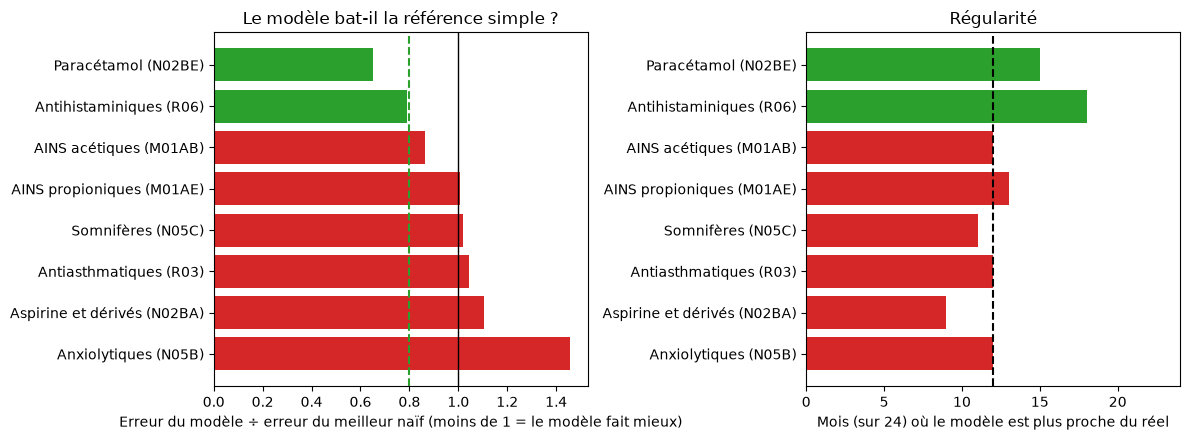

In [6]:
couleur = verdict["verdict"].map({"oui": "tab:green", "non": "tab:red"})
v = verdict.sort_values("rapport")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
a1.barh(v.index, v["rapport"], color=couleur[v.index])
a1.axvline(1, color="black", linewidth=1); a1.axvline(SEUIL, color="tab:green", linestyle="--")
a1.set_xlabel("Erreur du modèle ÷ erreur du meilleur naïf (moins de 1 = le modèle fait mieux)")
a1.set_title("Le modèle bat-il la référence simple ?"); a1.invert_yaxis()
a2.barh(v.index, v["mois_gagnes"], color=couleur[v.index]); a2.axvline(N_TEST / 2, color="black", linestyle="--")
a2.set_xlim(0, N_TEST); a2.set_xlabel(f"Mois (sur {N_TEST}) où le modèle est plus proche du réel")
a2.set_title("Régularité"); a2.invert_yaxis()
plt.tight_layout(); plt.show()

Erreur de chaque méthode.
De combien chaque méthode se trompe, en pourcentage des ventes mensuelles.

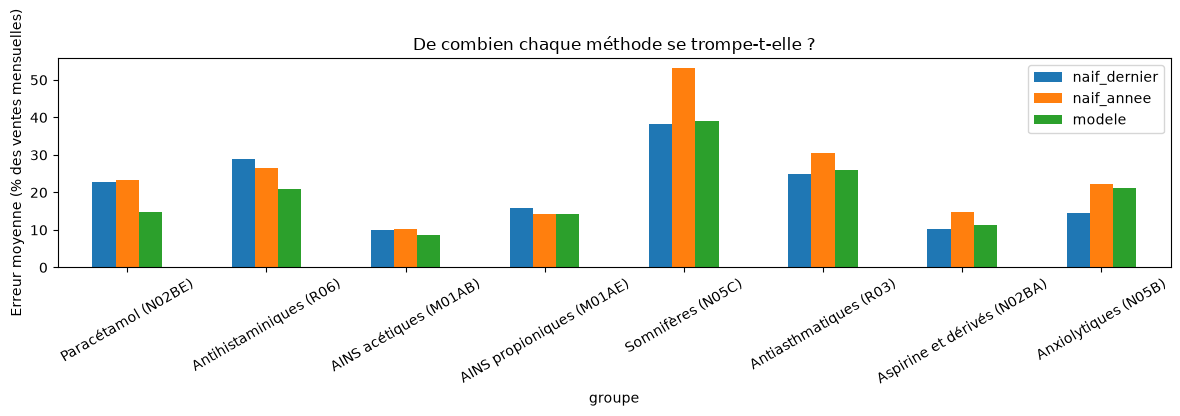

In [7]:
rel = mae[methodes].div(verdict["ventes_moyennes_mois"], axis=0) * 100
ax = rel.loc[v.index].plot.bar(figsize=(12, 4), rot=30)
ax.set_ylabel("Erreur moyenne (% des ventes mensuelles)")
ax.set_title("De combien chaque méthode se trompe-t-elle ?")
plt.tight_layout(); plt.show()

### Contrôle sans tendance
On refait le test sans la tendance pour vérifier que le verdict ne change pas.

In [8]:
# Controle de robustesse : meme test sans tendance (saisonnalite seule).
# Ne sert PAS a choisir le modele : on verifie seulement que le verdict ne depend pas de ce reglage.
lignes_b = []
for i in range(len(y) - N_TEST, len(y)):
    for g in groupes:
        lignes_b.append(holt_winters(y[g].iloc[:i].to_numpy(), trend=None))
sans_tendance = (pd.Series(lignes_b, index=test.index) - test["reel"]).abs().groupby(test["groupe"]).mean()
robustesse = pd.DataFrame({
    "rapport_modele": verdict["rapport"],
    "rapport_sans_tendance": sans_tendance / verdict["erreur_meilleur_naif"],
    "verdict": verdict["verdict"],
})
robustesse["meme_verdict"] = (robustesse["rapport_sans_tendance"] <= SEUIL) == (robustesse["verdict"] == "oui")
display(robustesse.sort_values("rapport_modele").round(2))

,rapport_modele,rapport_sans_tendance,verdict,meme_verdict
groupe,,,,
Paracétamol (N02BE),0.65,0.69,oui,True
Antihistaminiques (R06),0.79,0.78,oui,True
AINS acétiques (M01AB),0.86,0.89,non,True
AINS propioniques (M01AE),1.01,0.93,non,True
Somnifères (N05C),1.02,1.06,non,True
Antiasthmatiques (R03),1.04,1.01,non,True
Aspirine et dérivés (N02BA),1.11,1.09,non,True
Anxiolytiques (N05B),1.46,1.50,non,True


Verdict avec et sans tendance.
On compare les deux versions du modèle : si les barres sont proches, le verdict est stable.

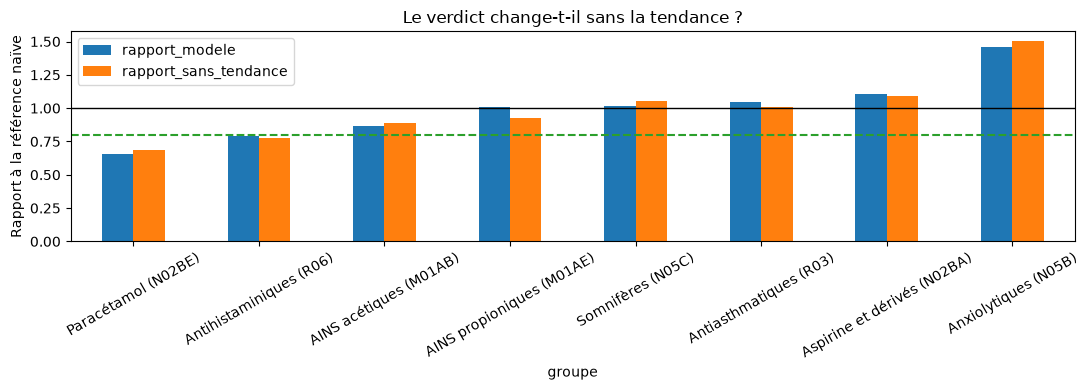

In [9]:
r = robustesse.sort_values("rapport_modele")
ax = r[["rapport_modele", "rapport_sans_tendance"]].plot.bar(figsize=(11, 4), rot=30)
ax.axhline(1, color="black", linewidth=1); ax.axhline(SEUIL, color="tab:green", linestyle="--")
ax.set_ylabel("Rapport à la référence naïve"); ax.set_title("Le verdict change-t-il sans la tendance ?")
plt.tight_layout(); plt.show()

### Prévision du mois suivant
La prévision du mois qui suit le dernier mois complet, seulement pour les groupes où la réponse est « oui ».

In [10]:
# Prevision du mois suivant le dernier mois complet, avec TOUTES les donnees (68 mois)
prochain = y.index[-1] + pd.offsets.MonthEnd(1)
prevision = pd.DataFrame({"prevision": {g: holt_winters(y[g].to_numpy()) for g in groupes}})
prevision["erreur_typique"] = verdict["erreur_modele"]          # ecart moyen constate pendant le test
prevision["verdict"] = verdict["verdict"]
fiable = prevision[prevision["verdict"] == "oui"]

print(f"Prévision pour {prochain:%m/%Y} (mois suivant le dernier mois complet), groupes où la réponse est « oui » :")
if len(fiable):
    display(fiable[["prevision", "erreur_typique"]].round(1))
else:
    print("aucun groupe : le modèle ne bat nettement la référence naïve nulle part")

Prévision pour 10/2019 (mois suivant le dernier mois complet), groupes où la réponse est « oui » :


,prevision,erreur_typique
Paracétamol (N02BE),1226.3,139.7
Antihistaminiques (R06),77.8,21.3


Prévision avec marge d'erreur.
La prévision et l'erreur habituelle observée pendant le test.

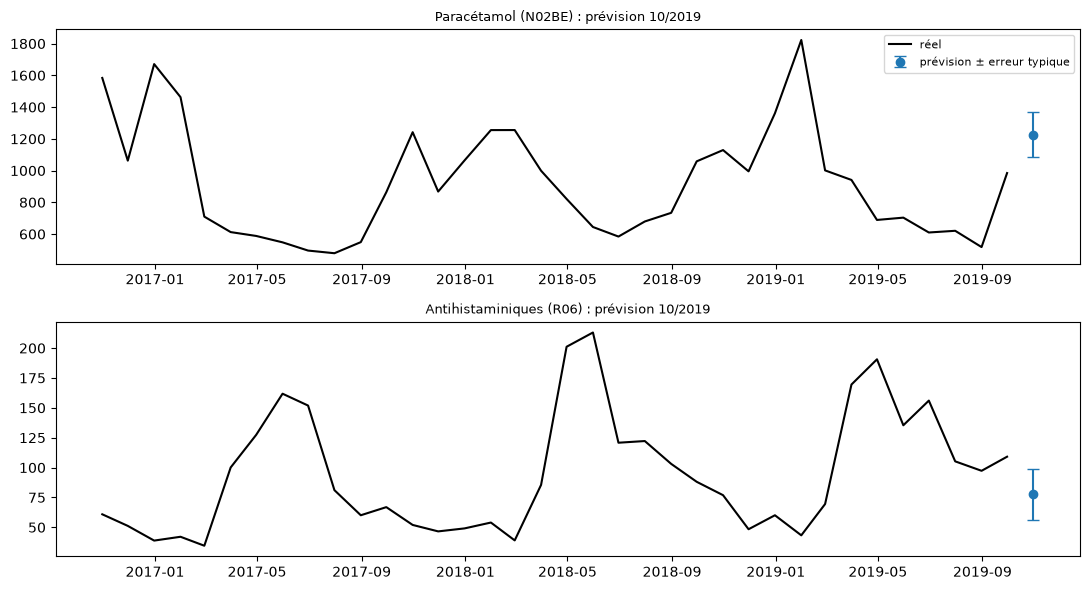

In [11]:
if len(fiable):
    fig, axes = plt.subplots(len(fiable), 1, figsize=(11, 3 * len(fiable)), squeeze=False)
    for ax, g in zip(axes.ravel(), fiable.index):
        ax.plot(y.index[-36:], y[g].iloc[-36:], color="black", label="réel")
        ax.errorbar([prochain], [fiable.loc[g, "prevision"]], yerr=fiable.loc[g, "erreur_typique"],
                    fmt="o", color="tab:blue", capsize=4, label="prévision ± erreur typique")
        ax.set_title(f"{g} : prévision {prochain:%m/%Y}", fontsize=9)
    axes[0, 0].legend(fontsize=8)
    plt.tight_layout(); plt.show()

In [12]:
from scipy.stats import binomtest
verdict["p_signes"] = [binomtest(int(k), N_TEST, 0.5, alternative="greater").pvalue
                       for k in verdict["mois_gagnes"]]
display(verdict[["rapport", "mois_gagnes", "p_signes", "verdict"]].sort_values("rapport").round(3))

,rapport,mois_gagnes,p_signes,verdict
groupe,,,,
Paracétamol (N02BE),0.652,15,0.154,oui
Antihistaminiques (R06),0.792,18,0.011,oui
AINS acétiques (M01AB),0.864,12,0.581,non
AINS propioniques (M01AE),1.005,13,0.419,non
Somnifères (N05C),1.020,11,0.729,non
Antiasthmatiques (R03),1.045,12,0.581,non
Aspirine et dérivés (N02BA),1.105,9,0.924,non
Anxiolytiques (N05B),1.455,12,0.581,non


### Modèle contre réalité
Pour chaque groupe, la courbe réelle, celle du modèle et celle du même mois l'an dernier. C'est une illustration, pas le test.

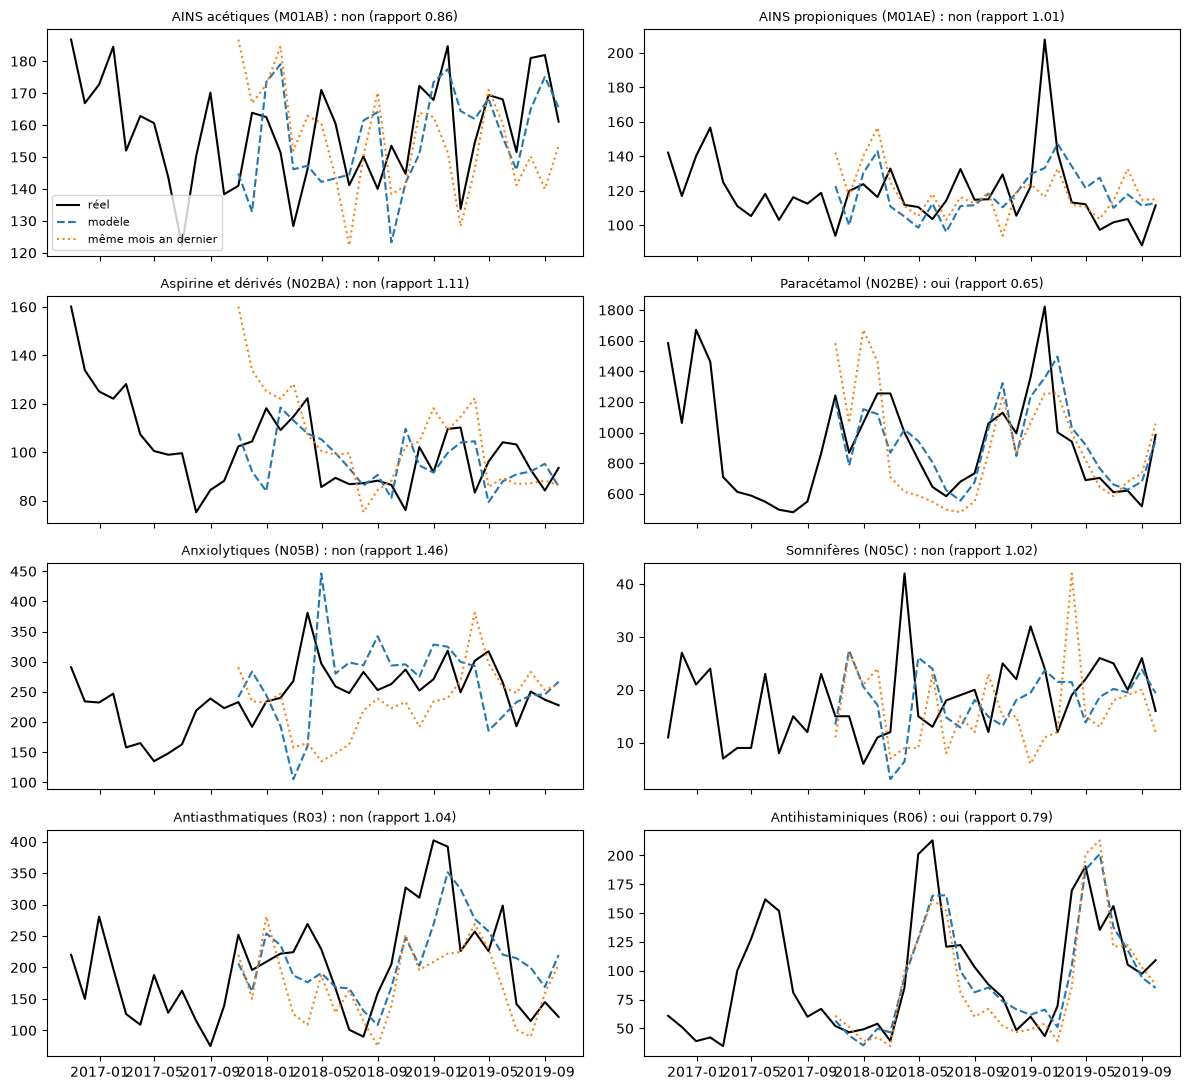

In [13]:
# Illustration (ce n'est pas le test : le test, c'est le tableau de verdict ci-dessus)
fig, axes = plt.subplots(4, 2, figsize=(12, 11), sharex=True)
for ax, g in zip(axes.ravel(), groupes):
    t = test[test["groupe"] == g].set_index("mois")
    ax.plot(y.index[-36:], y[g].iloc[-36:], color="black", label="réel")
    ax.plot(t.index, t["modele"], color="tab:blue", linestyle="--", label="modèle")
    ax.plot(t.index, t["naif_annee"], color="tab:orange", linestyle=":", label="même mois an dernier")
    ax.set_title(f'{g} : {verdict.loc[g, "verdict"]} (rapport {verdict.loc[g, "rapport"]:.2f})', fontsize=9)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Conclusions

**Réponse au manager : pour deux groupes sur huit.** (Chiffres du test sur les données jusqu'à septembre 2019 ; si les exports sont mis à jour, relire le tableau avant de réutiliser ces phrases.)

- **Paracétamol : oui, nettement.** Le modèle réduit l'erreur de 35 % par rapport à la meilleure référence naïve (rapport 0,65). Prévision pour octobre 2019 : environ 1 230 unités, avec une erreur typique de 140 (15 %).
- **Antihistaminiques : oui, de justesse.** Le rapport est de 0,79, tout juste sous le seuil de 0,8, mais le modèle fait mieux que la référence naïve dans 18 mois sur 24 et le verdict est le même sans tendance (0,78). Prévision pour octobre 2019 : environ 78 unités, avec une erreur typique de 21 (21 %) : c'est une indication de niveau, pas un chiffre précis.
- **AINS acétiques : non, pas assez net.** Gain de 14 % seulement (rapport 0,86).
- **AINS propioniques, somnifères, antiasthmatiques, aspirine, anxiolytiques : non.** Le modèle fait aussi bien ou moins bien que « le mois prochain sera comme ce mois-ci » (rapport de 1,01 à 1,46). Avec ces données, on ne peut pas annoncer de prévision utile pour ces groupes.

**Réserves à dire à l'oral**

- Le test porte sur 24 mois : c'est peu, un seul mois exceptionnel pèse sur la moyenne des erreurs.
- La période de test (octobre 2017 à septembre 2019) suit l'année 2017, anormalement basse pour des raisons inconnues (question à poser au client) : les modèles qui s'appuient sur l'historique en sont affectés.
- Le seuil de 0,8 est notre choix, pas une norme.
- Octobre 2019 n'a que 8 jours dans l'export : on ne peut pas vérifier la prévision du mois suivant.
- Les unités ne sont pas documentées : les erreurs sont en unités du logiciel de caisse, comparables seulement via le rapport ou l'erreur relative.